<a href="https://colab.research.google.com/github/PanconquesoHH/Laboratorios-ia/blob/main/LAB7PUNTO1Y2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random

# Cantidad aleatoria de centros
n_centers = random.randint(1, 20)

# Posiciones aleatorias de los centros
blob_centers = []

while len(blob_centers) < n_centers:
    candidate = np.random.uniform(-50, 50, size=2)

    # Aceptar el centro si está lejos de los anteriores
    if all(np.linalg.norm(candidate - center) > 10
           for center in blob_centers):
        blob_centers.append(candidate)

blob_centers = np.array(blob_centers)

# Dispersión aleatoria de los puntos de cada grupo
blob_std = np.random.uniform(0.5, 1.5, size=n_centers)

# Cantidad aleatoria de puntos de cada grupo
n_points = np.random.randint(50, 201, size=n_centers)

# Generar el dataset
X, y = make_blobs(
    n_samples=n_points.tolist(),
    centers=blob_centers,
    cluster_std=blob_std
)

# Mostrar información de los grupos generados
print("Cantidad de centros:", n_centers)
print("Total de puntos:", len(X))

for i in range(n_centers):
    print(
        f"Grupo {i}: "
        f"centro = {blob_centers[i].round(2)}, "
        f"puntos = {n_points[i]}, "
        f"dispersión = {blob_std[i]:.2f}"
    )

Cantidad de centros: 17
Total de puntos: 1914
Grupo 0: centro = [-39.4  -32.79], puntos = 68, dispersión = 1.49
Grupo 1: centro = [-27.78 -25.8 ], puntos = 55, dispersión = 1.30
Grupo 2: centro = [-2.88 13.88], puntos = 111, dispersión = 0.83
Grupo 3: centro = [-47.34 -38.96], puntos = 143, dispersión = 1.17
Grupo 4: centro = [  0.87 -31.57], puntos = 61, dispersión = 1.05
Grupo 5: centro = [-35.9   31.88], puntos = 161, dispersión = 1.16
Grupo 6: centro = [ 44.81 -35.21], puntos = 157, dispersión = 1.00
Grupo 7: centro = [-28.79  16.5 ], puntos = 64, dispersión = 1.26
Grupo 8: centro = [ 38.35 -24.61], puntos = 155, dispersión = 1.48
Grupo 9: centro = [-44.76 -15.6 ], puntos = 98, dispersión = 0.86
Grupo 10: centro = [ 34.18 -34.24], puntos = 101, dispersión = 0.90
Grupo 11: centro = [ 1.67 -9.54], puntos = 78, dispersión = 1.08
Grupo 12: centro = [-41.31  -0.41], puntos = 142, dispersión = 1.39
Grupo 13: centro = [-16.89  23.1 ], puntos = 111, dispersión = 1.35
Grupo 14: centro = [11

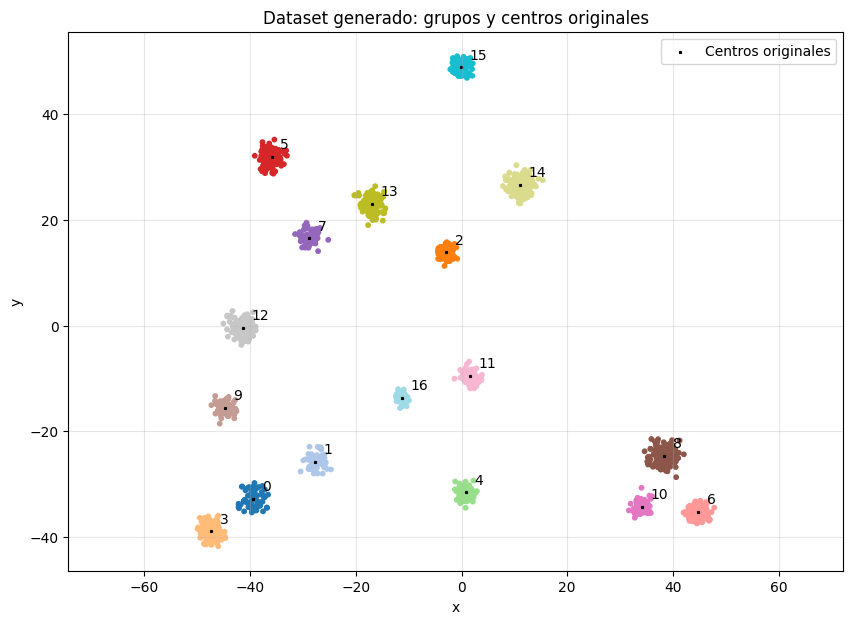

In [ ]:
# Función para graficar los puntos
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="tab20", s=10)
    plt.xlabel("x")
    plt.ylabel("y")

# Mostrar los grupos y sus centros originales
plt.figure(figsize=(10, 7))

plot_clusters(X, y)

plt.scatter(
    blob_centers[:, 0],
    blob_centers[:, 1],
    color="black",
    marker="X",
    s=2,
    label="Centros originales"
)

# Identificar cada centro con su número de grupo
for i in range(n_centers):
    plt.annotate(
        str(i),
        blob_centers[i],
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title("Dataset generado: grupos y centros originales")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()

In [ ]:
from sklearn.cluster import KMeans

# Usar la misma cantidad de grupos que generamos
k = n_centers

# Crear y entrenar el modelo
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)

# Obtener los centroides finales
final_centers = kmeans.cluster_centers_

print("Coordenadas de los centroides finales:")
print(final_centers.round(2))

Coordenadas de los centroides finales:
[[ 1.114e+01  2.650e+01]
 [-2.744e+01 -2.563e+01]
 [ 3.410e+01 -3.424e+01]
 [-3.603e+01  3.173e+01]
 [-1.130e+01 -1.364e+01]
 [-4.138e+01 -4.800e-01]
 [-4.731e+01 -3.896e+01]
 [-2.850e+00  1.386e+01]
 [-1.000e-02  4.900e+01]
 [-2.876e+01  1.678e+01]
 [ 7.400e-01 -3.164e+01]
 [-1.689e+01  2.297e+01]
 [-4.475e+01 -1.564e+01]
 [ 4.481e+01 -3.525e+01]
 [ 3.838e+01 -2.473e+01]
 [ 1.770e+00 -9.740e+00]
 [-3.934e+01 -3.286e+01]]


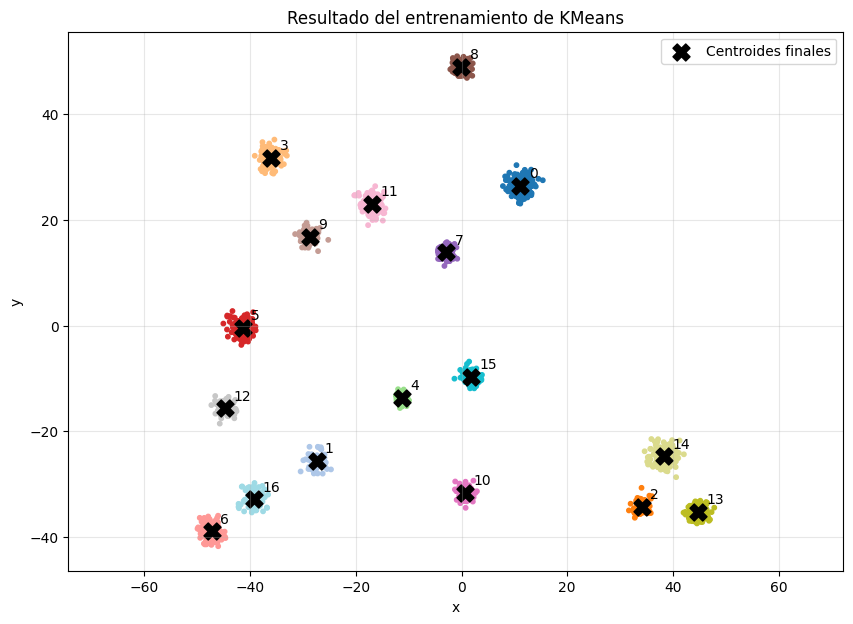

In [ ]:
plt.figure(figsize=(10, 7))

# Colorear según los grupos encontrados por KMeans
plot_clusters(X, y_pred)

# Mostrar los centroides finales
plt.scatter(
    final_centers[:, 0],
    final_centers[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Centroides finales"
)

for i in range(k):
    plt.annotate(
        str(i),
        final_centers[i],
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title("Resultado del entrenamiento de KMeans")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()

In [ ]:
# Guardar los cinco puntos más cercanos de cada grupo
closest_points = []

for i in range(k):
    # Seleccionar los puntos asignados a este grupo
    cluster_points = X[y_pred == i]

    # Calcular la distancia de cada punto a su centroide
    distances = np.linalg.norm(
        cluster_points - final_centers[i],
        axis=1
    )

    # Ordenar las distancias y seleccionar las cinco menores
    closest_indices = np.argsort(distances)[:5]
    nearest_points = cluster_points[closest_indices]

    closest_points.append(nearest_points)

    print(f"\nGrupo {i}")
    print("Centroide:", final_centers[i].round(2))
    print("Cantidad de puntos:", len(cluster_points))
    print("Cinco puntos más cercanos:")
    print(nearest_points.round(2))
    print("Distancias:", distances[closest_indices].round(3))


Grupo 0
Centroide: [11.14 26.5 ]
Cantidad de puntos: 171
Cinco puntos más cercanos:
[[11.12 26.47]
 [11.22 26.59]
 [11.   26.38]
 [10.93 26.6 ]
 [10.89 26.41]]
Distancias: [0.042 0.113 0.191 0.233 0.265]

Grupo 1
Centroide: [-27.44 -25.63]
Cantidad de puntos: 55
Cinco puntos más cercanos:
[[-27.22 -25.72]
 [-27.4  -26.06]
 [-27.02 -25.44]
 [-26.98 -25.25]
 [-27.68 -25.06]]
Distancias: [0.239 0.425 0.46  0.596 0.619]

Grupo 2
Centroide: [ 34.1  -34.24]
Cantidad de puntos: 101
Cinco puntos más cercanos:
[[ 34.03 -34.31]
 [ 34.22 -34.17]
 [ 34.11 -34.37]
 [ 34.28 -34.26]
 [ 34.14 -34.05]]
Distancias: [0.099 0.133 0.137 0.178 0.192]

Grupo 3
Centroide: [-36.03  31.73]
Cantidad de puntos: 161
Cinco puntos más cercanos:
[[-35.97  31.72]
 [-35.96  31.76]
 [-35.97  31.63]
 [-35.9   31.73]
 [-35.92  31.59]]
Distancias: [0.059 0.074 0.112 0.126 0.177]

Grupo 4
Centroide: [-11.3  -13.64]
Cantidad de puntos: 129
Cinco puntos más cercanos:
[[-11.25 -13.58]
 [-11.42 -13.56]
 [-11.38 -13.51]
 [-11.4

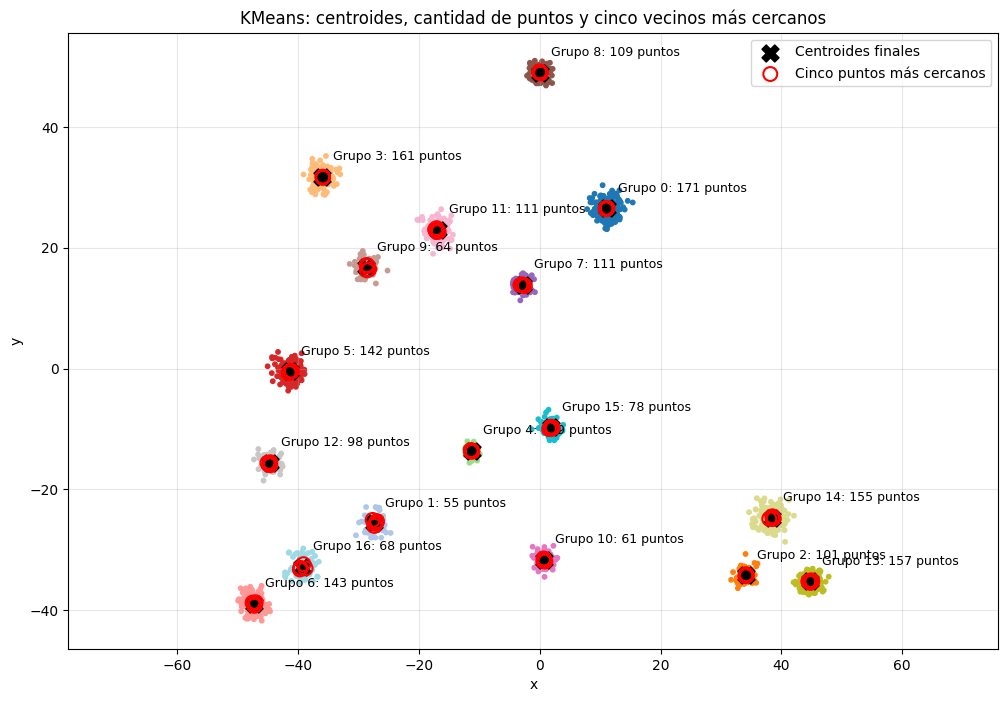

In [ ]:
plt.figure(figsize=(12, 8))

plot_clusters(X, y_pred)

# Mostrar los centroides finales
plt.scatter(
    final_centers[:, 0],
    final_centers[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Centroides finales",
    zorder=3
)

for i in range(k):
    nearest_points = closest_points[i]
    count = np.sum(y_pred == i)

    # Rodear los cinco puntos más cercanos
    plt.scatter(
        nearest_points[:, 0],
        nearest_points[:, 1],
        facecolors="none",
        edgecolors="red",
        s=100,
        linewidths=1.5,
        label="Cinco puntos más cercanos" if i == 0 else None,
        zorder=4
    )

    # Mostrar el grupo y su cantidad de puntos
    plt.annotate(
        f"Grupo {i}: {count} puntos",
        final_centers[i],
        xytext=(8, 12),
        textcoords="offset points",
        fontsize=9
    )

plt.title("KMeans: centroides, cantidad de puntos y cinco vecinos más cercanos")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()

/tmp/ipykernel_3473/4228157575.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[:, 0], X[:, 1], c=y, cmap="tab20", s=10)


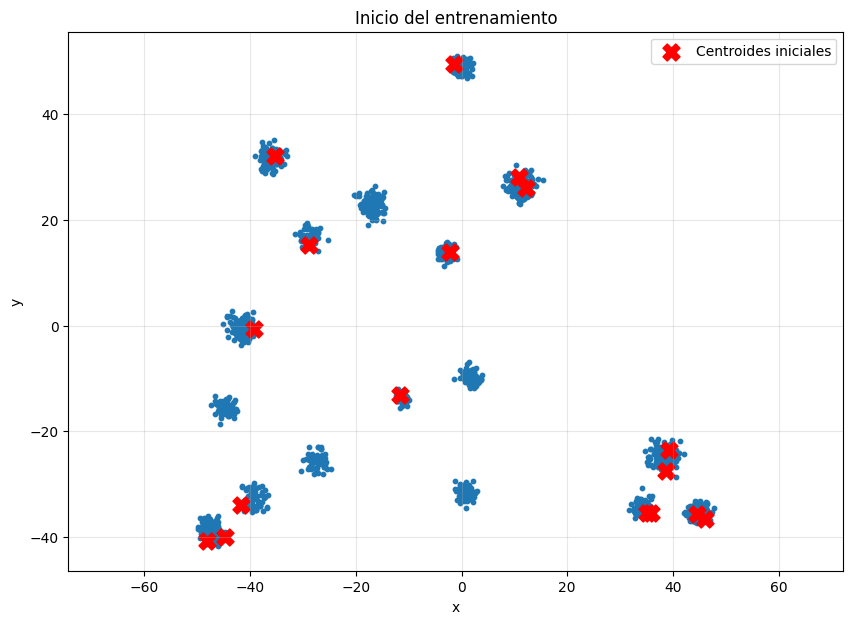

In [ ]:
# Elegir k puntos como centroides iniciales
rng = np.random.default_rng(42)
initial_indices = rng.choice(len(X), size=k, replace=False)
initial_centers = X[initial_indices]

plt.figure(figsize=(10, 7))

# Mostrar los puntos sin agrupar
plot_clusters(X)

plt.scatter(
    initial_centers[:, 0],
    initial_centers[:, 1],
    color="red",
    marker="X",
    s=150,
    label="Centroides iniciales"
)

plt.title("Inicio del entrenamiento")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()

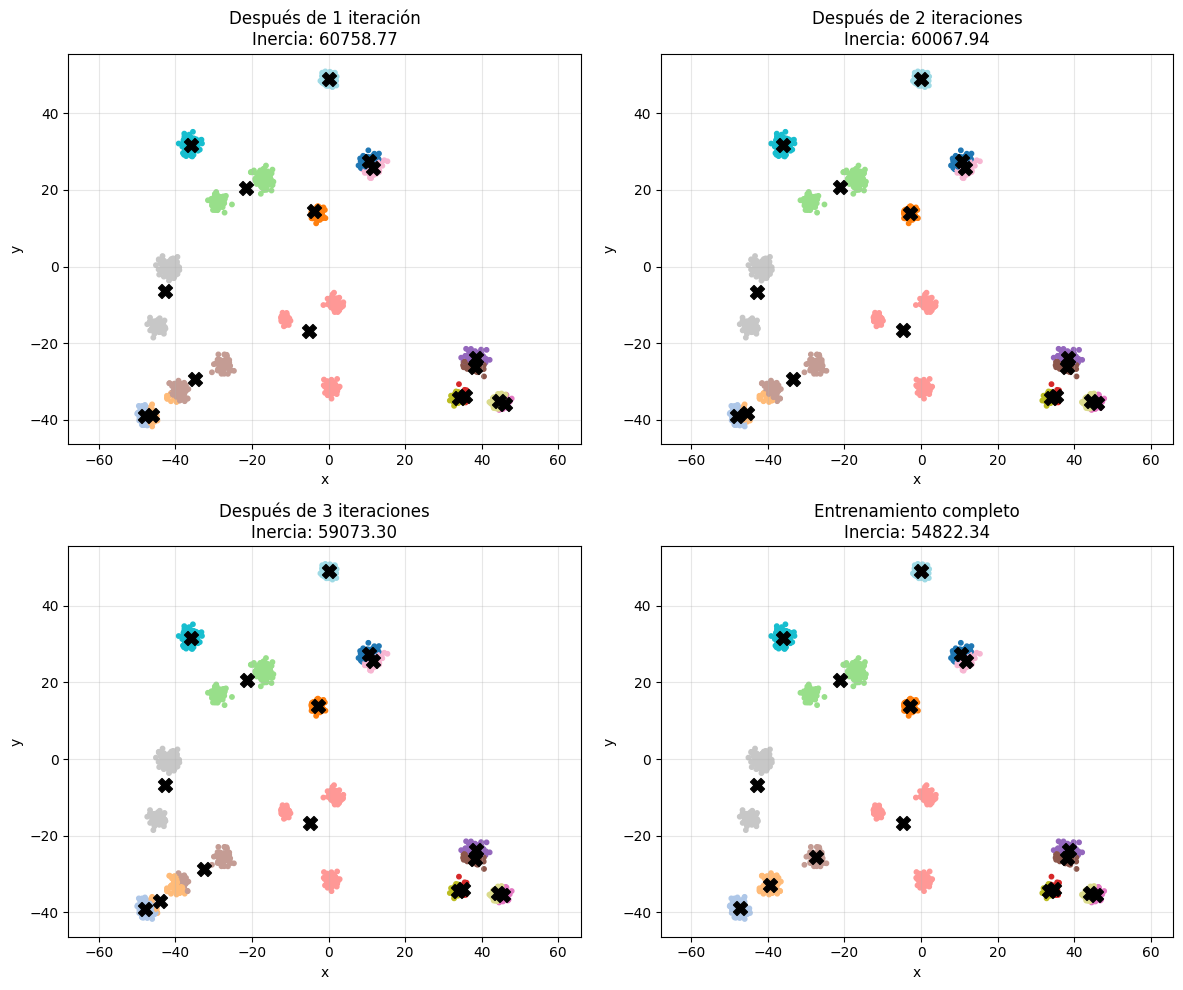

Iteraciones del entrenamiento completo: 6


In [ ]:
iteration_limits = [1, 2, 3, 300]
titles = ["Después de 1 iteración",
          "Después de 2 iteraciones",
          "Después de 3 iteraciones",
          "Entrenamiento completo"]

plt.figure(figsize=(12, 10))

for index, limit in enumerate(iteration_limits):
    model = KMeans(
        n_clusters=k,
        init=initial_centers.copy(),
        n_init=1,
        max_iter=limit,
        algorithm="lloyd",
        random_state=42
    )

    labels = model.fit_predict(X)
    centers = model.cluster_centers_

    plt.subplot(2, 2, index + 1)

    plot_clusters(X, labels)

    plt.scatter(
        centers[:, 0],
        centers[:, 1],
        color="black",
        marker="X",
        s=100,
        zorder=3
    )

    plt.title(f"{titles[index]}\nInercia: {model.inertia_:.2f}")
    plt.grid(alpha=0.3)
    plt.axis("equal")

plt.tight_layout()
plt.show()

print("Iteraciones del entrenamiento completo:", model.n_iter_)

In [ ]:
# Cantidad aleatoria de centros
n_centers_3d = random.randint(1, 20)

# Posiciones aleatorias de los centros en 3D
blob_centers_3d = []

while len(blob_centers_3d) < n_centers_3d:
    candidate = np.random.uniform(-50, 50, size=3)

    # Aceptar el centro si está lejos de los anteriores
    if all(np.linalg.norm(candidate - center) > 10
           for center in blob_centers_3d):
        blob_centers_3d.append(candidate)

blob_centers_3d = np.array(blob_centers_3d)

# Dispersión aleatoria de cada grupo
blob_std_3d = np.random.uniform(0.5, 1.5, size=n_centers_3d)

# Cantidad aleatoria de puntos de cada grupo
n_points_3d = np.random.randint(50, 201, size=n_centers_3d)

# Generar el dataset en 3D
X_3d, y_3d = make_blobs(
    n_samples=n_points_3d.tolist(),
    centers=blob_centers_3d,
    cluster_std=blob_std_3d
)

# Mostrar información de los grupos generados
print("Cantidad de centros:", n_centers_3d)
print("Total de puntos:", len(X_3d))
print("Forma del dataset:", X_3d.shape)

for i in range(n_centers_3d):
    print(
        f"Grupo {i}: "
        f"centro = {blob_centers_3d[i].round(2)}, "
        f"puntos = {n_points_3d[i]}, "
        f"dispersión = {blob_std_3d[i]:.2f}"
    )

Cantidad de centros: 16
Total de puntos: 1905
Forma del dataset: (1905, 3)
Grupo 0: centro = [-12.31  41.63   7.48], puntos = 65, dispersión = 0.63
Grupo 1: centro = [-25.82  41.77 -42.88], puntos = 139, dispersión = 0.51
Grupo 2: centro = [ -3.62  19.63 -41.76], puntos = 120, dispersión = 1.15
Grupo 3: centro = [-39.15  45.03  36.44], puntos = 97, dispersión = 1.04
Grupo 4: centro = [-31.43  -7.27 -30.22], puntos = 153, dispersión = 1.19
Grupo 5: centro = [ 23.45   6.91 -29.47], puntos = 53, dispersión = 1.14
Grupo 6: centro = [-0.9  38.9  13.13], puntos = 101, dispersión = 1.09
Grupo 7: centro = [ 38.34   2.29 -48.37], puntos = 97, dispersión = 1.48
Grupo 8: centro = [ 49.94  21.64 -29.27], puntos = 108, dispersión = 0.57
Grupo 9: centro = [32.4  38.19 42.09], puntos = 172, dispersión = 1.31
Grupo 10: centro = [-12.42  40.83  40.41], puntos = 168, dispersión = 1.30
Grupo 11: centro = [-13.16  10.9  -25.88], puntos = 65, dispersión = 1.47
Grupo 12: centro = [-33.3    8.87 -23.38], pun

In [ ]:
# Cantidad aleatoria de centros
n_centers_3d = random.randint(1, 20)

# Posiciones aleatorias de los centros en 3D
blob_centers_3d = []

while len(blob_centers_3d) < n_centers_3d:
    candidate = np.random.uniform(-50, 50, size=3)

    # Aceptar el centro si está lejos de los anteriores
    if all(np.linalg.norm(candidate - center) > 10
           for center in blob_centers_3d):
        blob_centers_3d.append(candidate)

blob_centers_3d = np.array(blob_centers_3d)

# Dispersión aleatoria de cada grupo
blob_std_3d = np.random.uniform(0.5, 1.5, size=n_centers_3d)

# Cantidad aleatoria de puntos de cada grupo
n_points_3d = np.random.randint(50, 201, size=n_centers_3d)

# Generar el dataset en 3D
X_3d, y_3d = make_blobs(
    n_samples=n_points_3d.tolist(),
    centers=blob_centers_3d,
    cluster_std=blob_std_3d
)

# Mostrar información de los grupos generados
print("Cantidad de centros:", n_centers_3d)
print("Total de puntos:", len(X_3d))
print("Forma del dataset:", X_3d.shape)

for i in range(n_centers_3d):
    print(
        f"Grupo {i}: "
        f"centro = {blob_centers_3d[i].round(2)}, "
        f"puntos = {n_points_3d[i]}, "
        f"dispersión = {blob_std_3d[i]:.2f}"
    )

Cantidad de centros: 12
Total de puntos: 1556
Forma del dataset: (1556, 3)
Grupo 0: centro = [ 13.26 -18.78 -44.41], puntos = 116, dispersión = 1.32
Grupo 1: centro = [-47.01 -33.59 -33.56], puntos = 142, dispersión = 1.32
Grupo 2: centro = [-46.64  -3.72  20.98], puntos = 159, dispersión = 1.47
Grupo 3: centro = [31.61 20.35 41.39], puntos = 194, dispersión = 0.86
Grupo 4: centro = [-18.53 -29.09  -1.02], puntos = 145, dispersión = 0.86
Grupo 5: centro = [-36.99  38.98 -19.84], puntos = 150, dispersión = 0.53
Grupo 6: centro = [-18.94  43.13 -18.24], puntos = 55, dispersión = 1.42
Grupo 7: centro = [-46.06  30.76 -26.21], puntos = 146, dispersión = 0.77
Grupo 8: centro = [ 46.99 -36.47  -6.74], puntos = 92, dispersión = 1.41
Grupo 9: centro = [-10.22 -11.35  18.83], puntos = 157, dispersión = 1.05
Grupo 10: centro = [ 49.86  45.44 -23.81], puntos = 99, dispersión = 1.40
Grupo 11: centro = [ 24.96 -22.5   27.47], puntos = 101, dispersión = 0.74


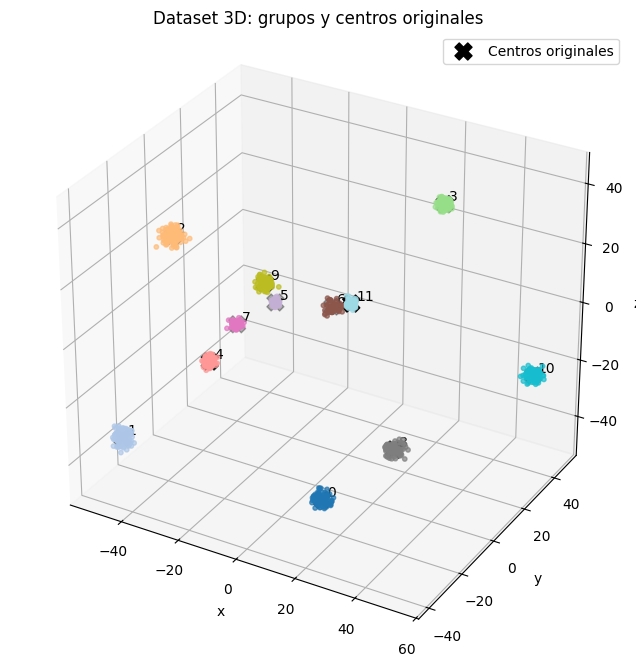

In [ ]:
# Función para graficar los puntos en 3D
def plot_clusters_3d(ax, X, y=None):
    ax.scatter(
        X[:, 0], X[:, 1], X[:, 2],
        c=y,
        cmap="tab20",
        s=10,
        alpha=0.7
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

# Crear una gráfica tridimensional
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

plot_clusters_3d(ax, X_3d, y_3d)

# Mostrar los centros originales
ax.scatter(
    blob_centers_3d[:, 0],
    blob_centers_3d[:, 1],
    blob_centers_3d[:, 2],
    color="black",
    marker="X",
    s=150,
    label="Centros originales"
)

# Identificar cada centro
for i in range(n_centers_3d):
    x, y, z = blob_centers_3d[i]
    ax.text(x + 1, y + 1, z + 1, str(i))

# Mantener una escala comparable en los tres ejes
ax.set_box_aspect(np.ptp(X_3d, axis=0))

ax.set_title("Dataset 3D: grupos y centros originales")
ax.legend()
plt.show()

In [ ]:
# Cantidad de grupos que debe encontrar
k_3d = n_centers_3d

# Crear y entrenar el modelo
kmeans_3d = KMeans(
    n_clusters=k_3d,
    n_init=10,
    random_state=42
)

y_pred_3d = kmeans_3d.fit_predict(X_3d)

# Obtener los centroides finales
final_centers_3d = kmeans_3d.cluster_centers_

print("Coordenadas de los centroides finales:")

for i in range(k_3d):
    print(f"Grupo {i}: {final_centers_3d[i].round(2)}")

Coordenadas de los centroides finales:
Grupo 0: [ 47.07 -36.6   -6.64]
Grupo 1: [-46.58  -3.85  21.03]
Grupo 2: [ 24.92 -22.47  27.38]
Grupo 3: [-18.77  43.55 -18.56]
Grupo 4: [-46.91 -33.58 -33.51]
Grupo 5: [31.54 20.39 41.41]
Grupo 6: [ 49.83  45.39 -23.68]
Grupo 7: [-10.23 -11.27  18.76]
Grupo 8: [ 13.16 -18.82 -44.4 ]
Grupo 9: [-36.95  38.96 -19.83]
Grupo 10: [-18.6  -29.1   -0.96]
Grupo 11: [-46.06  30.68 -26.23]


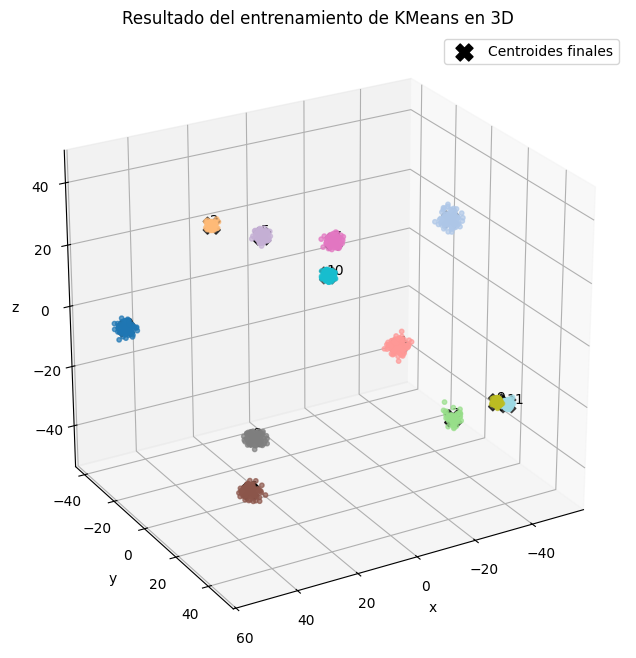

In [ ]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Colorear según los grupos encontrados por KMeans
plot_clusters_3d(ax, X_3d, y_pred_3d)

# Mostrar los centroides finales
ax.scatter(
    final_centers_3d[:, 0],
    final_centers_3d[:, 1],
    final_centers_3d[:, 2],
    color="black",
    marker="X",
    s=150,
    label="Centroides finales"
)

# Identificar cada centroide
for i in range(k_3d):
    x, y, z = final_centers_3d[i]
    ax.text(x + 1, y + 1, z + 1, str(i))

ax.set_box_aspect(np.ptp(X_3d, axis=0))
ax.view_init(elev=25, azim=60)

ax.set_title("Resultado del entrenamiento de KMeans en 3D")
ax.legend()
plt.show()

In [ ]:
# Guardar los cinco puntos más cercanos de cada grupo
closest_points_3d = []

for i in range(k_3d):
    # Seleccionar los puntos del grupo
    cluster_points = X_3d[y_pred_3d == i]

    # Calcular las distancias al centroide en 3D
    distances = np.linalg.norm(
        cluster_points - final_centers_3d[i],
        axis=1
    )

    # Seleccionar las cinco distancias menores
    closest_indices = np.argsort(distances)[:5]
    nearest_points = cluster_points[closest_indices]

    closest_points_3d.append(nearest_points)

    print(f"\nGrupo {i}")
    print("Centroide:", final_centers_3d[i].round(2))
    print("Cantidad de puntos:", len(cluster_points))
    print("Cinco puntos más cercanos:")
    print(nearest_points.round(2))
    print("Distancias:", distances[closest_indices].round(3))


Grupo 0
Centroide: [ 47.07 -36.6   -6.64]
Cantidad de puntos: 92
Cinco puntos más cercanos:
[[ 47.32 -36.93  -6.58]
 [ 46.71 -36.43  -7.08]
 [ 47.08 -36.3   -7.25]
 [ 46.8  -36.14  -6.01]
 [ 46.97 -35.8   -6.39]]
Distancias: [0.421 0.599 0.679 0.832 0.847]

Grupo 1
Centroide: [-46.58  -3.85  21.03]
Cantidad de puntos: 159
Cinco puntos más cercanos:
[[-46.71  -4.14  20.81]
 [-46.49  -4.05  21.37]
 [-46.33  -3.5   20.86]
 [-46.38  -4.28  21.1 ]
 [-46.01  -3.49  20.97]]
Distancias: [0.387 0.405 0.462 0.479 0.675]

Grupo 2
Centroide: [ 24.92 -22.47  27.38]
Cantidad de puntos: 101
Cinco puntos más cercanos:
[[ 24.82 -22.5   27.49]
 [ 24.71 -22.32  27.4 ]
 [ 25.11 -22.14  27.44]
 [ 24.94 -22.04  27.27]
 [ 24.64 -22.42  27.72]]
Distancias: [0.157 0.258 0.382 0.44  0.448]

Grupo 3
Centroide: [-18.77  43.55 -18.56]
Cantidad de puntos: 55
Cinco puntos más cercanos:
[[-18.99  43.52 -18.36]
 [-18.43  43.83 -18.83]
 [-18.    43.92 -18.63]
 [-18.29  43.41 -17.71]
 [-18.48  43.28 -17.65]]
Distancias

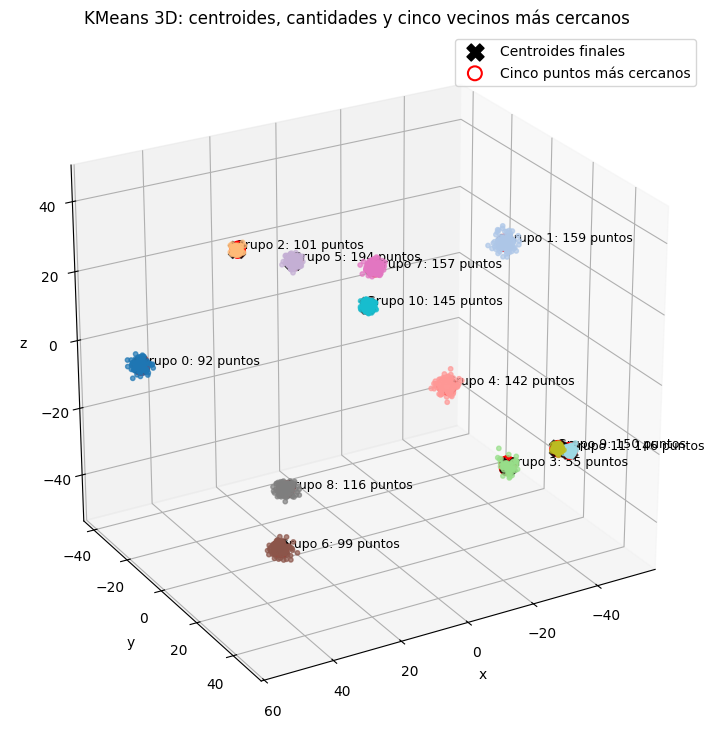

In [ ]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

plot_clusters_3d(ax, X_3d, y_pred_3d)

# Mostrar los centroides finales
ax.scatter(
    final_centers_3d[:, 0],
    final_centers_3d[:, 1],
    final_centers_3d[:, 2],
    color="black",
    marker="X",
    s=150,
    label="Centroides finales"
)

for i in range(k_3d):
    nearest_points = closest_points_3d[i]
    count = np.sum(y_pred_3d == i)

    # Rodear los cinco puntos más cercanos
    ax.scatter(
        nearest_points[:, 0],
        nearest_points[:, 1],
        nearest_points[:, 2],
        facecolors="none",
        edgecolors="red",
        s=100,
        linewidths=1.5,
        depthshade=False,
        label="Cinco puntos más cercanos" if i == 0 else None
    )

    # Mostrar el grupo y su cantidad de puntos
    x, y, z = final_centers_3d[i]
    ax.text(
        x + 1, y + 1, z + 1,
        f"Grupo {i}: {count} puntos",
        fontsize=9
    )

ax.set_box_aspect(np.ptp(X_3d, axis=0))
ax.view_init(elev=25, azim=60)

ax.set_title("KMeans 3D: centroides, cantidades y cinco vecinos más cercanos")
ax.legend()
plt.show()

/tmp/ipykernel_3473/1870731827.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(


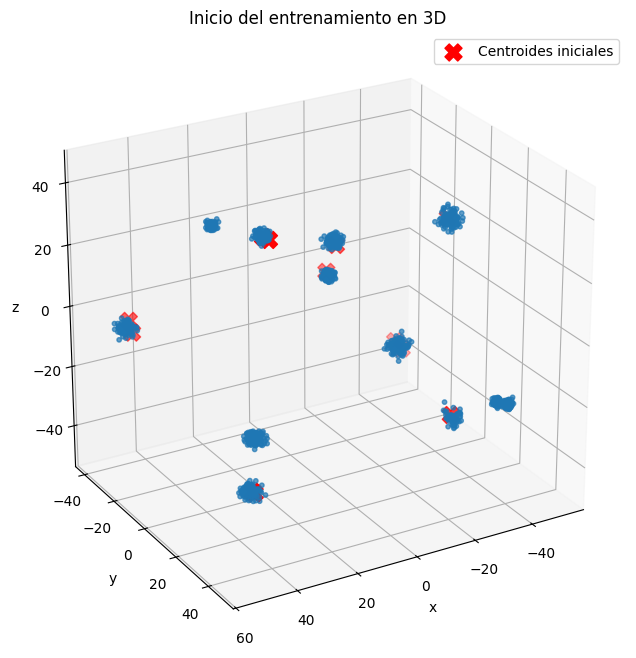

In [ ]:
# Elegir k puntos como centroides iniciales
rng_3d = np.random.default_rng(42)
initial_indices_3d = rng_3d.choice(
    len(X_3d), size=k_3d, replace=False
)

initial_centers_3d = X_3d[initial_indices_3d]

# Graficar las posiciones iniciales
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

plot_clusters_3d(ax, X_3d)

ax.scatter(
    initial_centers_3d[:, 0],
    initial_centers_3d[:, 1],
    initial_centers_3d[:, 2],
    color="red",
    marker="X",
    s=150,
    label="Centroides iniciales"
)

ax.set_box_aspect(np.ptp(X_3d, axis=0))
ax.view_init(elev=25, azim=60)
ax.set_title("Inicio del entrenamiento en 3D")
ax.legend()
plt.show()

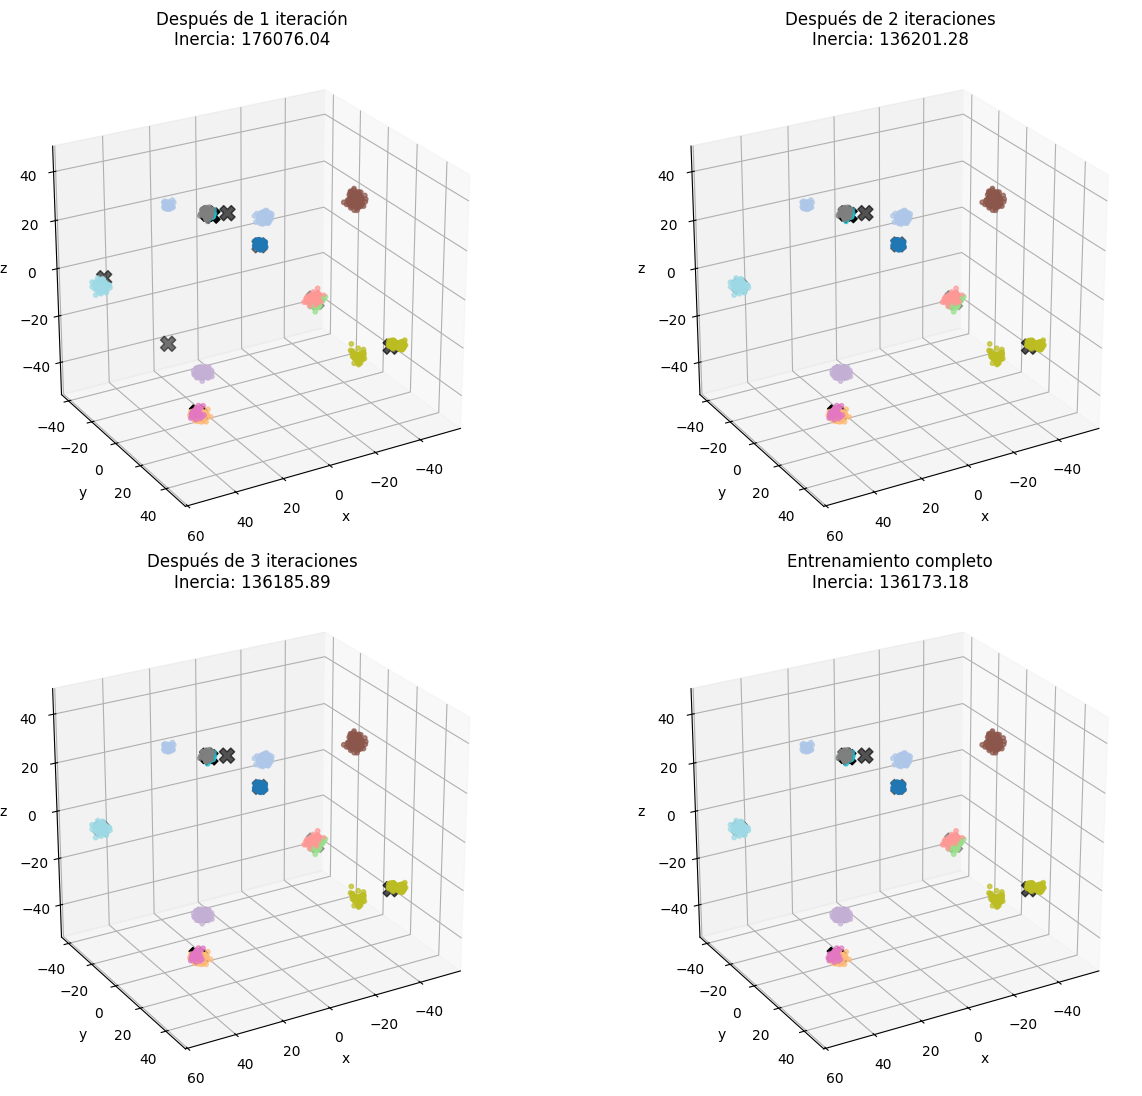

Iteraciones del entrenamiento completo: 4


In [ ]:
iteration_limits = [1, 2, 3, 300]

titles = [
    "Después de 1 iteración",
    "Después de 2 iteraciones",
    "Después de 3 iteraciones",
    "Entrenamiento completo"
]

fig = plt.figure(figsize=(14, 11))

for index, limit in enumerate(iteration_limits):
    model_3d = KMeans(
        n_clusters=k_3d,
        init=initial_centers_3d.copy(),
        n_init=1,
        max_iter=limit,
        algorithm="lloyd",
        random_state=42
    )

    labels = model_3d.fit_predict(X_3d)
    centers = model_3d.cluster_centers_

    ax = fig.add_subplot(2, 2, index + 1, projection="3d")

    plot_clusters_3d(ax, X_3d, labels)

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        centers[:, 2],
        color="black",
        marker="X",
        s=120
    )

    ax.set_box_aspect(np.ptp(X_3d, axis=0))
    ax.view_init(elev=25, azim=60)

    ax.set_title(
        f"{titles[index]}\nInercia: {model_3d.inertia_:.2f}"
    )

plt.tight_layout()
plt.show()

print(
    "Iteraciones del entrenamiento completo:",
    model_3d.n_iter_
)